# Lab 07 — Contrastive image–text alignment: a tiny CLIP, then the real one

**Book sections:** [4.1 Contrastive learning](../../book/docs/chapters/04-alignment/contrastive.md),
[4.2 CLIP and SigLIP](../../book/docs/chapters/04-alignment/clip-siglip.md),
[4.5 Failure modes](../../book/docs/chapters/04-alignment/failure-modes.md).

**Goal.** Implement the InfoNCE loss by hand and check it against the reference; train a tiny CLIP on
depot scenes and their captions; use it for retrieval and zero-shot classification; probe whether it
binds colours to objects and understands left/right (the "bag of words" problem);
train the same model with the SigLIP loss; repeat the probes with the real CLIP ViT-B/32; and measure
the modality gap.

**Runtime:** ≈4 min with a GPU, ≈25 min on CPU. **Downloads:** ≈600 MB (CLIP ViT-B/32).
**GPU:** optional (< 2 GB). **Seed:** 0. **Writes** `data/checkpoints/tiny_clip.pt`, reused by Lab 08.

In [1]:
import os
import random
import time
from pathlib import Path

os.environ.setdefault("HF_HOME", str(Path("../../data/hf").resolve()))

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

from vlacourse.clip import TinyCLIP, clip_loss, siglip_loss
from vlacourse.data import scenes
from vlacourse.seed import device, set_seed
from vlacourse.vision import to_tensor

set_seed(0)
dev = device()
CKPT = Path("../../data/checkpoints/tiny_clip.pt")
print("device:", dev)

device: cuda


## 1. Data: scenes and captions
12 000 scenes with 1–3 objects; captions such as *"a red toolbox left of a blue crate"*. Captions are
tokenized with the scene vocabulary (word level, 42 words) and end with `<eos>`, whose output vector is
the sentence embedding (as in CLIP's text tower).

In [2]:
N_TRAIN, N_TEST = 11_000, 1_000
sc, im = scenes.scene_dataset(N_TRAIN + N_TEST, seed=0)
X = to_tensor(im)                                                      # (N, 3, 64, 64)
caps = [scenes.caption(s) for s in sc]


def tokenize(texts):
    seqs = [scenes.encode(t) + [scenes.EOS] for t in texts]
    ids = torch.full((len(seqs), max(map(len, seqs))), scenes.PAD)
    for i, s in enumerate(seqs):
        ids[i, :len(s)] = torch.tensor(s)
    return ids, torch.tensor([len(s) - 1 for s in seqs])               # ids (n, T), position of <eos>


ids, eos = tokenize(caps)
print("images", tuple(X.shape), " caption ids", tuple(ids.shape))
for i in range(3):
    print(f"  {caps[i]!r:55} -> {ids[i].tolist()}")
print("distinct captions:", len(set(caps)), "for", len(caps), "images")

images (12000, 3, 64, 64)  caption ids (12000, 12)
  'a blue cone above a red toolbox'                       -> [6, 13, 17, 7, 6, 30, 35, 2, 0, 0, 0, 0]
  'a green toolbox, a yellow cone and a red crate'        -> [6, 20, 35, 4, 6, 40, 17, 9, 6, 30, 18, 2]
  'a red barrel, a green crate and a yellow crate'        -> [6, 30, 11, 4, 6, 20, 18, 9, 6, 40, 18, 2]
distinct captions: 3063 for 12000 images


## 2. InfoNCE by hand
For a batch of $B$ pairs with normalised embeddings $\mathbf{u}_i$ (image) and $\mathbf{v}_j$ (text),
logits $s_{ij}=\mathbf{u}_i\mathbf{v}_j^\top/\tau$. Row $i$ is a $B$-way classification "which caption is
image $i$'s?", column $j$ the reverse; CLIP averages the two cross-entropies (book 4.1).

In [3]:
def info_nce_by_hand(u, v, tau):
    s = u @ v.T / tau                                                  # (B, B)
    log_p_rows = s - s.logsumexp(dim=1, keepdim=True)                  # softmax over captions, per image
    log_p_cols = s - s.logsumexp(dim=0, keepdim=True)                  # softmax over images, per caption
    return -(log_p_rows.diag().mean() + log_p_cols.diag().mean()) / 2


u = F.normalize(torch.randn(8, 16), dim=-1)
v = F.normalize(u + 0.3 * torch.randn(8, 16), dim=-1)
tau = 0.07
print("by hand  ", info_nce_by_hand(u, v, tau).item())
print("reference", clip_loss(u, v, torch.tensor(np.log(1 / tau))).item())
print("chance level log B =", np.log(8), "(uninformative embeddings)")

by hand   0.010795772075653076
reference 0.01079573854804039
chance level log B = 2.0794415416798357 (uninformative embeddings)


## 3. Train the tiny CLIP
ViT image tower (64×64, $P=8$, 4 layers, $d=128$), causal text tower (3 layers), projections to a
64-dimensional joint space, learned temperature initialised at 0.07 as in CLIP.

trained in 108 s; final loss 0.655, learned 1/temperature 18.5


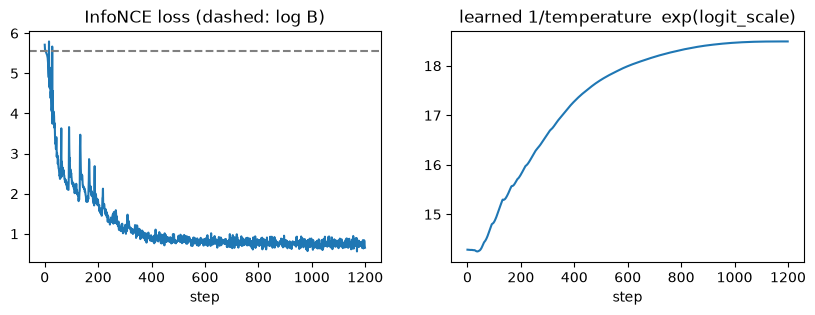

In [4]:
def train(loss_name, steps=1200, B=256, seed=0):
    set_seed(seed)
    m = TinyCLIP(len(scenes.VOCAB)).to(dev)
    opt = torch.optim.AdamW(m.parameters(), lr=1e-3, weight_decay=0.05)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, 1e-3, total_steps=steps, pct_start=0.05)
    hist = []
    for step in range(steps):
        j = torch.randint(0, N_TRAIN, (B,))
        u = m.encode_image(X[j].to(dev))
        v = m.encode_text(ids[j].to(dev), eos[j].to(dev))
        loss = clip_loss(u, v, m.logit_scale) if loss_name == "clip" else siglip_loss(u, v, m.logit_scale, m.logit_bias)
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
        hist.append((loss.item(), m.logit_scale.exp().item()))
    return m.eval(), np.array(hist)


t0 = time.time()
clip_model, hist = train("clip")
print(f"trained in {time.time() - t0:.0f} s; final loss {hist[-1, 0]:.3f}, learned 1/temperature {hist[-1, 1]:.1f}")
CKPT.parent.mkdir(parents=True, exist_ok=True)
torch.save(clip_model.state_dict(), CKPT)

fig, axs = plt.subplots(1, 2, figsize=(10, 3))
axs[0].plot(hist[:, 0]); axs[0].axhline(np.log(256), ls="--", c="gray"); axs[0].set_title("InfoNCE loss (dashed: log B)")
axs[1].plot(hist[:, 1]); axs[1].set_title("learned 1/temperature  exp(logit_scale)")
for a in axs:
    a.set_xlabel("step")
plt.show()

## 4. Retrieval and zero-shot classification
**Retrieval:** for each test image, rank all distinct test captions; correct if the top caption is the
image's caption. **Zero-shot classification:** on new single-object scenes, embed the 16 prompts
*"a {colour} {kind}"* and pick the most similar — no classifier was ever trained.

In [5]:
@torch.no_grad()
def embed_images(m, Xs):
    return torch.cat([m.encode_image(Xs[k:k + 500].to(dev)) for k in range(0, len(Xs), 500)])


@torch.no_grad()
def embed_texts(m, texts):
    i_, e_ = tokenize(texts)
    return m.encode_text(i_.to(dev), e_.to(dev))


test_caps = caps[N_TRAIN:]
uniq = sorted(set(test_caps))


def retrieval_acc(m):
    S = embed_images(m, X[N_TRAIN:]) @ embed_texts(m, uniq).T          # (N_test, n_captions)
    return np.mean([uniq[k] == c for k, c in zip(S.argmax(1).tolist(), test_caps)])


one_sc, one_im = scenes.scene_dataset(1000, seed=5, n_objects=1)
one_X = to_tensor(one_im)
classes = [f"{c} {k}" for k in scenes.KINDS for c in scenes.COLORS]
one_y = [classes.index(f"{s.objects[0].color} {s.objects[0].kind}") for s in one_sc]


def zero_shot_acc(m):
    S = embed_images(m, one_X) @ embed_texts(m, [f"a {c}" for c in classes]).T
    return np.mean(np.array(S.argmax(1).tolist()) == np.array(one_y))


print(f"caption retrieval top-1 among {len(uniq)} captions: {retrieval_acc(clip_model):.3f}")
print(f"zero-shot 16-way classification: {zero_shot_acc(clip_model):.3f}  (chance 0.0625)")

caption retrieval top-1 among 609 captions: 0.822
zero-shot 16-way classification: 1.000  (chance 0.0625)


## 5. Does it bind attributes and understand relations?
On two-object test scenes compare the true caption with two hard negatives built from the *same words*:

* **attribute swap** — *"a red toolbox left of a blue crate"* vs *"a blue toolbox left of a red crate"*;
* **object swap** — vs *"a blue crate left of a red toolbox"* (same objects, wrong spatial order).

A model that represents a caption as a bag of words scores both negatives exactly like the truth.

In [6]:
two = [(i, s) for i, s in enumerate(sc[N_TRAIN:], start=N_TRAIN) if len(s.objects) == 2]


def probes(m):
    U = embed_images(m, X[[i for i, _ in two]])
    res = {"attribute swap": [], "object swap": []}
    for (i, s), u in zip(two, U):
        a, b = sorted(s.objects, key=lambda o: o.x)
        rel = scenes.relation(a, b)
        true = f"a {a.color} {a.kind} {rel} a {b.color} {b.kind}"
        neg = {"attribute swap": f"a {b.color} {a.kind} {rel} a {a.color} {b.kind}",
               "object swap": f"a {b.color} {b.kind} {rel} a {a.color} {a.kind}"}
        for k, n in neg.items():
            if a.color != b.color and a.kind != b.kind:
                t = embed_texts(m, [true, n])
                res[k].append((u @ t.T)[0] > (u @ t.T)[1])
    return {k: float(torch.stack(v).float().mean()) for k, v in res.items()}


print("tiny CLIP picks the true caption over the hard negative:", probes(clip_model), "(chance 0.5)")

tiny CLIP picks the true caption over the hard negative: {'attribute swap': 1.0, 'object swap': 0.8277778029441833} (chance 0.5)


Our tiny CLIP binds colours almost perfectly and gets the spatial order right most of the time. Its world
is tiny: 42 words and ~3000 distinct captions, so a batch of 256 often contains captions that differ only
in which colour goes with which object, and the loss *forces* it to learn binding. Keep these numbers in
mind for §7, where the real CLIP, trained on web captions, faces the same probes.

## 6. The same model with the SigLIP loss
The sigmoid loss scores each of the $B^2$ pairs independently: no softmax across the batch (book 4.2).

In [7]:
t0 = time.time()
siglip_model, hist_s = train("siglip")
print(f"SigLIP trained in {time.time() - t0:.0f} s; learned 1/temperature {hist_s[-1, 1]:.1f}, "
      f"bias {siglip_model.logit_bias.item():.2f}")
print(f"retrieval {retrieval_acc(siglip_model):.3f}   zero-shot {zero_shot_acc(siglip_model):.3f}   probes {probes(siglip_model)}")

SigLIP trained in 108 s; learned 1/temperature 13.9, bias -9.80


retrieval 0.761   zero-shot 1.000   probes {'attribute swap': 1.0, 'object swap': 0.6555555462837219}


In this single small run the sigmoid loss is a little behind the softmax loss. Do not read much into one
run: Zhai et al. (2023) find the sigmoid loss as good or better, especially at small batch sizes, and its
decisive advantage is systems-level — no batch-wide normalisation, so the $B\times B$ similarity matrix can
be computed in chunks across devices and the batch can be scaled cheaply.

## 7. The real thing: CLIP ViT-B/32
12-layer ViT with $P=32$ on 224×224 images (49 patches), a 12-layer text transformer, 512-d joint space,
trained on 400 M web image–text pairs. Our renders are far from its training distribution — like a
robot's camera images.

In [8]:
from transformers import CLIPModel, CLIPProcessor

clip_hf = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(dev).eval()
proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
print(f"params {sum(p.numel() for p in clip_hf.parameters()) / 1e6:.0f} M; "
      f"learned 1/temperature {clip_hf.logit_scale.exp().item():.1f}")


@torch.no_grad()
def hf_embed(images=None, texts=None):
    if images is not None:
        x = proc(images=list(images), return_tensors="pt")["pixel_values"].to(dev)
        return F.normalize(clip_hf.get_image_features(pixel_values=x).pooler_output, dim=-1)   # projected [CLS]
    t = proc(text=texts, return_tensors="pt", padding=True).to(dev)
    return F.normalize(clip_hf.get_text_features(**t).pooler_output, dim=-1)        # projected <eos>


big = np.stack([scenes.render(s, 224, size=0.3) for s in one_sc[:300]])
U = hf_embed(images=big)
for template in ["a {}", "a photo of a {}.", "a top-down photo of a {} on a concrete floor."]:
    S = U @ hf_embed(texts=[template.format(c) for c in classes]).T
    acc = np.mean(np.array(S.argmax(1).tolist()) == np.array(one_y[:300]))
    kind_acc = np.mean([classes[p].split()[1] == classes[t].split()[1] for p, t in zip(S.argmax(1).tolist(), one_y)])
    col_acc = np.mean([classes[p].split()[0] == classes[t].split()[0] for p, t in zip(S.argmax(1).tolist(), one_y)])
    print(f"{template!r:52} 16-way {acc:.2f}   kind {kind_acc:.2f}   colour {col_acc:.2f}")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

params 151 M; learned 1/temperature 100.0


'a {}'                                               16-way 0.69   kind 0.69   colour 1.00
'a photo of a {}.'                                   16-way 0.72   kind 0.72   colour 1.00
'a top-down photo of a {} on a concrete floor.'      16-way 0.95   kind 0.95   colour 1.00


Prompt wording changes zero-shot accuracy — a practical fact about every CLIP-like model. Now the binding
probe on two-object scenes:

In [9]:
pairs = [s for s in sc[N_TRAIN:] if len(s.objects) == 2 and len({o.color for o in s.objects}) == 2
         and len({o.kind for o in s.objects}) == 2][:300]
U2 = hf_embed(images=np.stack([scenes.render(s, 224, size=0.3) for s in pairs]))
wins = {"attribute swap": [], "object swap": []}
for s, u in zip(pairs, U2):
    a, b = sorted(s.objects, key=lambda o: o.x)
    true = f"a photo of a {a.color} {a.kind} to the left of a {b.color} {b.kind}."
    negs = {"attribute swap": f"a photo of a {b.color} {a.kind} to the left of a {a.color} {b.kind}.",
            "object swap": f"a photo of a {b.color} {b.kind} to the left of a {a.color} {a.kind}."}
    for k, n in negs.items():
        t = hf_embed(texts=[true, n])
        wins[k].append(bool((u @ t.T)[0] > (u @ t.T)[1]))
print({k: round(float(np.mean(v)), 3) for k, v in wins.items()}, "(chance 0.5)")

{'attribute swap': 0.494, 'object swap': 0.544} (chance 0.5)


A model trained on 400 M pairs, which recognises every colour in §7, is at chance both at binding colours
to the right objects and at deciding *which* object is on the left — where our tiny model succeeded.
Contrastive training rewards whatever
distinguishes a caption from the *other captions in the batch*; random batches rarely contain two captions
that differ only in word order, so word order is barely learned (book 4.5). For a robot told to "pick up the
red toolbox left of the crate", that is exactly the information that matters.

## 8. The modality gap
Both towers output unit vectors — but do images and captions occupy the same region of the sphere?

tiny CLIP  matched pairs cos 0.91 | image-image 0.03 | text-text 0.04 | centroid distance 0.06


CLIP B/32  matched pairs cos 0.30 | image-image 0.87 | text-text 0.70 | centroid distance 1.04


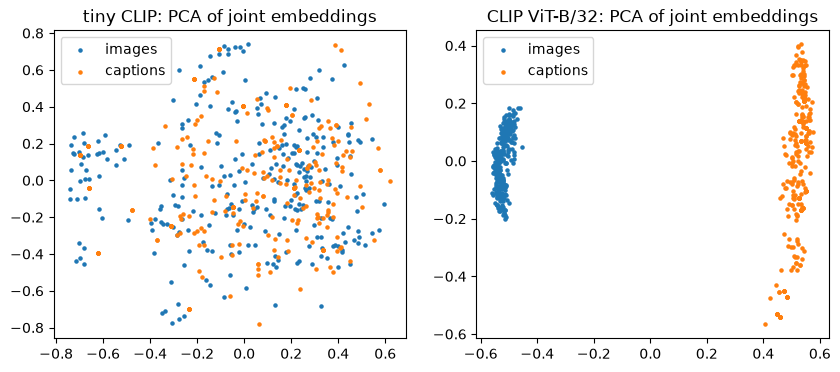

In [10]:
def gap_report(name, U, Vt):
    U, Vt = U.float().cpu(), Vt.float().cpu()
    print(f"{name:10} matched pairs cos {(U * Vt).sum(-1).mean():.2f} | image-image {(U @ U.roll(1, 0).T).diag().mean():.2f}"
          f" | text-text {(Vt @ Vt.roll(1, 0).T).diag().mean():.2f} | centroid distance {(U.mean(0) - Vt.mean(0)).norm():.2f}")
    return U, Vt


gap_scenes = sc[N_TRAIN:N_TRAIN + 300]
Ut, Vtt = gap_report("tiny CLIP", embed_images(clip_model, X[N_TRAIN:N_TRAIN + 300]), embed_texts(clip_model, test_caps[:300]))
Uh, Vh = gap_report("CLIP B/32",
                    hf_embed(images=np.stack([scenes.render(s, 224, size=0.3) for s in gap_scenes])),
                    hf_embed(texts=[f"a photo of {c}." for c in test_caps[:300]]))
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, U, Vt) in zip(axs, [("tiny CLIP", Ut, Vtt), ("CLIP ViT-B/32", Uh, Vh)]):
    Z = torch.cat([U, Vt])
    Z = Z - Z.mean(0)
    pc = Z @ torch.linalg.svd(Z, full_matrices=False)[2][:2].T
    ax.scatter(*pc[:300].T, s=5, label="images")
    ax.scatter(*pc[300:].T, s=5, label="captions")
    ax.set_title(f"{name}: PCA of joint embeddings"); ax.legend()
plt.show()

The real CLIP shows the **modality gap** (Liang et al., 2022): matched image–caption pairs have cosine
similarity around 0.3 although each modality is tightly clustered; images and texts form two separate
clouds, and the first principal component simply says "image or text". Retrieval still works, because
only the *ranking* within one modality matters. But anything that mixes the two spaces naively
(averaging an image and a text embedding, or a threshold on raw similarity) inherits the gap. Our tiny
model, trained to a much lower loss on a closed world, has almost none: the gap comes from how large
models are initialised and trained, not from the loss formula alone.

## Exercises
1. Train the tiny CLIP with batch size 32 and 1024 (same number of *examples*). How do retrieval and the
   probes change? Relate this to the number of negatives per step.
2. Add hard negatives to training: for every two-object caption, append its object-swapped version as an
   extra text that must *not* match. Does the object-swap probe improve?
3. Freeze the temperature at 1.0 and at 0.01. What happens to training, and why (book 4.1)?
4. Compute the tiny CLIP's similarity between every patch token (projected) and the text "a red toolbox".
   Does it localise the object? Why is this not guaranteed by the training objective?
5. Robotics: a drone uses CLIP to flag frames that contain "a red toolbox". Using §8, estimate the false
   positive rate on frames containing a red *crate*. What would you change before trusting it?